# **Question 12: K-Means Clustering**

##### **Aim**: Use the four numerical attributes of the Iris dataset to group flowers into three clusters without using Species during clustering. Apply K-Means, plot the clusters using two attributes report the cluster assignments.

###### **Experiment reference**: Experiment 8

In [27]:
# Step 1: Import the required libraries

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [28]:
# Step 2: Load the Iris dataset

iris = pd.read_csv('/content/Iris.csv')
df=pd.DataFrame(iris)
print("Shape of dataset : ",df.shape)
print("\n")
display(df.head())

Shape of dataset :  (150, 6)




,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [44]:
# Step 3: Use the four numerical attributes of the Iris dataset to group flowers into three clusters without using Species during clustering

cols=['SepalLengthCm','SepalWidthCm','PetalLengthCm','PetalWidthCm']
X=df[cols]
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

print("Input feature Shape:",X_scaled.shape)
print("CLustering input contains Species:",'Species' in X.columns)

Input feature Shape: (150, 4)
CLustering input contains Species: False


In [45]:
# Step 4: Run K-Means with three reproducible clusters

kmeans=KMeans(n_clusters=3, n_init=10,random_state=42)
clusters=kmeans.fit_predict(X_scaled)
clustered=X.copy()
clustered['Cluster']=clusters
print("First 10 cluster assignments :",clusters[0:10])
print("cluster size:\n")
print(clustered['Cluster'].value_counts())
print()
display(clustered[['SepalLengthCm','PetalLengthCm','Cluster']].head(10))

First 10 cluster assignments : [1 1 1 1 1 1 1 1 1 1]
cluster size:

Cluster
0    53
1    50
2    47
Name: count, dtype: int64



,SepalLengthCm,PetalLengthCm,Cluster
0,5.1,1.4,1
1,4.9,1.4,1
2,4.7,1.3,1
3,4.6,1.5,1
4,5.0,1.4,1
5,5.4,1.7,1
6,4.6,1.4,1
7,5.0,1.5,1
8,4.4,1.4,1
9,4.9,1.5,1


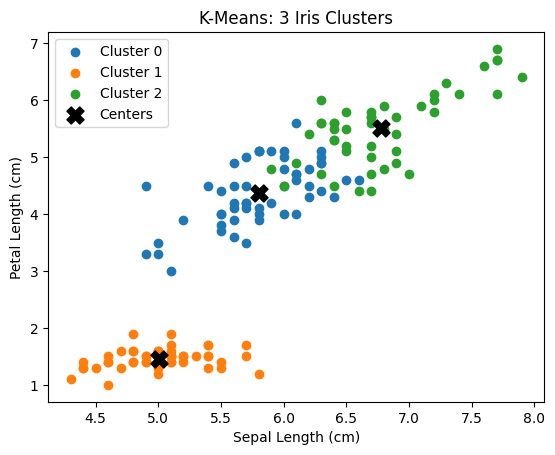

In [46]:
# Step 5: Visualize clusters using two original attributes

centers = scaler.inverse_transform(kmeans.cluster_centers_)

for c in range(3):
    group = clustered[clustered['Cluster'] == c]
    plt.scatter(group['SepalLengthCm'], group['PetalLengthCm'], label=f'Cluster {c}')

plt.scatter(centers[:, 0], centers[:, 2], marker='X', c='black', s=150, label='Centers')
plt.title('K-Means: 3 Iris Clusters')
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Petal Length (cm)')
plt.legend()
plt.show()

In [51]:
# Step 6: Report cluster centers (back in centimetres)

display(pd.DataFrame(centers, columns=cols))
print()
print("Observation: K-Means groups flowers by feature similarity without using the Species labels")

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.801887,2.673585,4.369811,1.413208
1,5.006000,3.428000,1.462000,0.246000
2,6.780851,3.095745,5.510638,1.972340



Observation: K-Means groups flowers by feature similarity without using the Species labels
